In [90]:
!pip install xgboost lightgbm catboost

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

In [91]:
df = pd.read_csv('/content/laptopData.csv')
df

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1.0,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2.0,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3.0,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080
...,...,...,...,...,...,...,...,...,...,...,...,...
1298,1298.0,Lenovo,2 in 1 Convertible,14,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.8kg,33992.6400
1299,1299.0,Lenovo,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16GB,512GB SSD,Intel HD Graphics 520,Windows 10,1.3kg,79866.7200
1300,1300.0,Lenovo,Notebook,14,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,64GB Flash Storage,Intel HD Graphics,Windows 10,1.5kg,12201.1200
1301,1301.0,HP,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6GB,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19kg,40705.9200


In [92]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1273 non-null   float64
 1   Company           1273 non-null   object 
 2   TypeName          1273 non-null   object 
 3   Inches            1273 non-null   object 
 4   ScreenResolution  1273 non-null   object 
 5   Cpu               1273 non-null   object 
 6   Ram               1273 non-null   object 
 7   Memory            1273 non-null   object 
 8   Gpu               1273 non-null   object 
 9   OpSys             1273 non-null   object 
 10  Weight            1273 non-null   object 
 11  Price             1273 non-null   float64
dtypes: float64(2), object(10)
memory usage: 122.3+ KB


In [93]:
df.describe()

,Unnamed: 0,Price
count,1273.000000,1273.000000
mean,652.674784,59955.814073
std,376.493027,37332.251005
min,0.000000,9270.720000
25%,327.000000,31914.720000
50%,652.000000,52161.120000
75%,980.000000,79333.387200
max,1302.000000,324954.720000


In [94]:
df.shape

(1303, 12)

In [95]:
df.duplicated().sum()

np.int64(29)

In [96]:
df.drop_duplicates(inplace=True)

In [97]:
df.isnull().sum()

,0
Unnamed: 0,1
Company,1
TypeName,1
Inches,1
ScreenResolution,1
Cpu,1
Ram,1
Memory,1
Gpu,1
OpSys,1


In [98]:
df.dropna(inplace=True)

In [99]:
df.drop(['Unnamed: 0'],axis=1,inplace=True)

In [100]:
df.reset_index(drop=True,inplace=True)

In [101]:
df

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080
...,...,...,...,...,...,...,...,...,...,...,...
1268,Lenovo,2 in 1 Convertible,14,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.8kg,33992.6400
1269,Lenovo,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16GB,512GB SSD,Intel HD Graphics 520,Windows 10,1.3kg,79866.7200
1270,Lenovo,Notebook,14,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,64GB Flash Storage,Intel HD Graphics,Windows 10,1.5kg,12201.1200
1271,HP,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6GB,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19kg,40705.9200


In [102]:
df['Ram'] = df['Ram'].replace('GB', '', regex=True).astype('int32')

# Remove 'kg', convert to numeric coercing errors like '?' to NaN, then drop NaNs
df['Weight'] = df['Weight'].str.replace('kg', '', regex=True)
df['Weight'] = pd.to_numeric(df['Weight'], errors='coerce')
df.dropna(subset=['Weight'], inplace=True)
df['Weight'] = df['Weight'].astype('float32')

In [103]:
for i in df.select_dtypes('object').columns:
  print(i)
  print(df[i].nunique())
  print('-'*20)

Company
19
--------------------
TypeName
6
--------------------
Inches
25
--------------------
ScreenResolution
40
--------------------
Cpu
118
--------------------
Memory
40
--------------------
Gpu
110
--------------------
OpSys
9
--------------------


In [104]:
# from sklearn.preprocessing import LabelEncoder
# le = LabelEncoder()
# for i in df.select_dtypes('object').columns:
#   df[i] = le.fit_transform(df[i])



In [105]:
import re
import pandas as pd
import numpy as np

# Reload the raw dataset to have clean categorical columns for processing
df_raw = pd.read_csv('/content/laptopData.csv')
df_raw.dropna(subset=['Cpu', 'Gpu', 'Memory'], inplace=True)

# --- 1. Clean CPU Column ---
# Extract CPU GHz
df_raw['Cpu_Speed_GHz'] = df_raw['Cpu'].str.extract(r'(\d+\.?\d*)GHz').astype(float)

# Extract CPU Brand (First word of the Cpu string)
df_raw['Cpu_Brand'] = df_raw['Cpu'].str.split().str[0]

# Extract CPU Type (Everything except the brand and GHz speed)
def get_cpu_type(cpu_str):
    cpu_str = re.sub(r'\s*\d+\.?\d*GHz', '', cpu_str) # Remove GHz speed
    words = cpu_str.split()
    if len(words) > 1:
        return ' '.join(words[1:]) # Drop the brand name (first word)
    return 'Other'

df_raw['Cpu_Type'] = df_raw['Cpu'].apply(get_cpu_type)

# --- 2. Clean GPU Column ---
# Extract GPU Brand (First word)
df_raw['Gpu_Brand'] = df_raw['Gpu'].str.split().str[0]

# Extract GPU Type (Everything after the first word)
df_raw['Gpu_Type'] = df_raw['Gpu'].apply(lambda x: ' '.join(x.split()[1:]) if len(x.split()) > 1 else 'Other')

# --- 3. Clean Memory Column ---
# Clean storage size to only contain numbers (converting TB to GB as 1024)
def extract_storage_gb(memory_str):
    memory_str = str(memory_str).upper()
    # Find patterns like '128GB' or '1TB'
    matches = re.findall(r'(\d+)\s*(GB|TB)', memory_str)
    total_gb = 0
    for value, unit in matches:
        val = int(value)
        if unit == 'TB':
            val *= 1024
        total_gb += val
    return total_gb if total_gb > 0 else np.nan

def extract_memory_type(memory_str):
    memory_str = str(memory_str).upper()
    types = []
    if 'SSD' in memory_str:
        types.append('SSD')
    if 'HDD' in memory_str:
        types.append('HDD')
    if 'FLASH' in memory_str or 'EMMC' in memory_str:
        types.append('Flash Storage')
    if 'HYBRID' in memory_str:
        types.append('Hybrid')
    return '+'.join(types) if types else 'Other'

df_raw['Memory_Size_GB'] = df_raw['Memory'].apply(extract_storage_gb)
df_raw['Memory_Type'] = df_raw['Memory'].apply(extract_memory_type)

# Update main df with the newly extracted features
for col in ['Cpu_Speed_GHz', 'Cpu_Brand', 'Cpu_Type', 'Gpu_Brand', 'Gpu_Type', 'Memory_Size_GB', 'Memory_Type']:
    df[col] = df_raw[col]

display(df[['Cpu', 'Cpu_Brand', 'Cpu_Type', 'Cpu_Speed_GHz', 'Gpu', 'Gpu_Brand', 'Gpu_Type', 'Memory', 'Memory_Size_GB', 'Memory_Type']].head())


,Cpu,Cpu_Brand,Cpu_Type,Cpu_Speed_GHz,Gpu,Gpu_Brand,Gpu_Type,Memory,Memory_Size_GB,Memory_Type
0,Intel Core i5 2.3GHz,Intel,Core i5,2.3,Intel Iris Plus Graphics 640,Intel,Iris Plus Graphics 640,128GB SSD,128.0,SSD
1,Intel Core i5 1.8GHz,Intel,Core i5,1.8,Intel HD Graphics 6000,Intel,HD Graphics 6000,128GB Flash Storage,128.0,Flash Storage
2,Intel Core i5 7200U 2.5GHz,Intel,Core i5 7200U,2.5,Intel HD Graphics 620,Intel,HD Graphics 620,256GB SSD,256.0,SSD
3,Intel Core i7 2.7GHz,Intel,Core i7,2.7,AMD Radeon Pro 455,AMD,Radeon Pro 455,512GB SSD,512.0,SSD
4,Intel Core i5 3.1GHz,Intel,Core i5,3.1,Intel Iris Plus Graphics 650,Intel,Iris Plus Graphics 650,256GB SSD,256.0,SSD


In [106]:
df

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price,Cpu_Speed_GHz,Cpu_Brand,Cpu_Type,Gpu_Brand,Gpu_Type,Memory_Size_GB,Memory_Type
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,71378.6832,2.3,Intel,Core i5,Intel,Iris Plus Graphics 640,128.0,SSD
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,47895.5232,1.8,Intel,Core i5,Intel,HD Graphics 6000,128.0,Flash Storage
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,30636.0000,2.5,Intel,Core i5 7200U,Intel,HD Graphics 620,256.0,SSD
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,135195.3360,2.7,Intel,Core i7,AMD,Radeon Pro 455,512.0,SSD
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,96095.8080,3.1,Intel,Core i5,Intel,Iris Plus Graphics 650,256.0,SSD
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1268,Lenovo,2 in 1 Convertible,14,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4,128GB SSD,Intel HD Graphics 520,Windows 10,1.80,33992.6400,1.6,Intel,Celeron Dual Core N3060,Intel,HD Graphics 400,32.0,Flash Storage
1269,Lenovo,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16,512GB SSD,Intel HD Graphics 520,Windows 10,1.30,79866.7200,2.5,Intel,Core i7 6500U,Nvidia,GeForce 920M,500.0,HDD
1270,Lenovo,Notebook,14,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2,64GB Flash Storage,Intel HD Graphics,Windows 10,1.50,12201.1200,2.5,Intel,Core i7 6500U,Intel,HD Graphics 520,128.0,SSD
1271,HP,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19,40705.9200,2.5,Intel,Core i7 6500U,Intel,HD Graphics 520,512.0,SSD


In [107]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for i in df.select_dtypes('object').columns:
  df[i] = le.fit_transform(df[i])

In [108]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1272 entries, 0 to 1272
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Company           1272 non-null   int64  
 1   TypeName          1272 non-null   int64  
 2   Inches            1272 non-null   int64  
 3   ScreenResolution  1272 non-null   int64  
 4   Cpu               1272 non-null   int64  
 5   Ram               1272 non-null   int32  
 6   Memory            1272 non-null   int64  
 7   Gpu               1272 non-null   int64  
 8   OpSys             1272 non-null   int64  
 9   Weight            1272 non-null   float32
 10  Price             1272 non-null   float64
 11  Cpu_Speed_GHz     1242 non-null   float64
 12  Cpu_Brand         1272 non-null   int64  
 13  Cpu_Type          1272 non-null   int64  
 14  Gpu_Brand         1272 non-null   int64  
 15  Gpu_Type          1272 non-null   int64  
 16  Memory_Size_GB    1233 non-null   float64
 17  

In [109]:
X=df.drop('Price',axis=1)
y=df['Price']

In [110]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
#

In [111]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Identify categorical and numeric columns
cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()
num_cols = X_train.select_dtypes(exclude=['object']).columns.tolist()

# Apply One-Hot Encoding to categorical columns, keeping train and test aligned
X_train_encoded = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_test_encoded = pd.get_dummies(X_test, columns=cat_cols, drop_first=True)

# Align columns so both train and test have exactly the same dummy columns
X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

# Handle potential NaN values resulting from newly extracted columns in previous steps
X_train_encoded.fillna(0, inplace=True)
X_test_encoded.fillna(0, inplace=True)

# Apply StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train_encoded)
X_test = sc.transform(X_test_encoded)

In [112]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [113]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]/tmp/ipykernel_6057/2174430653.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


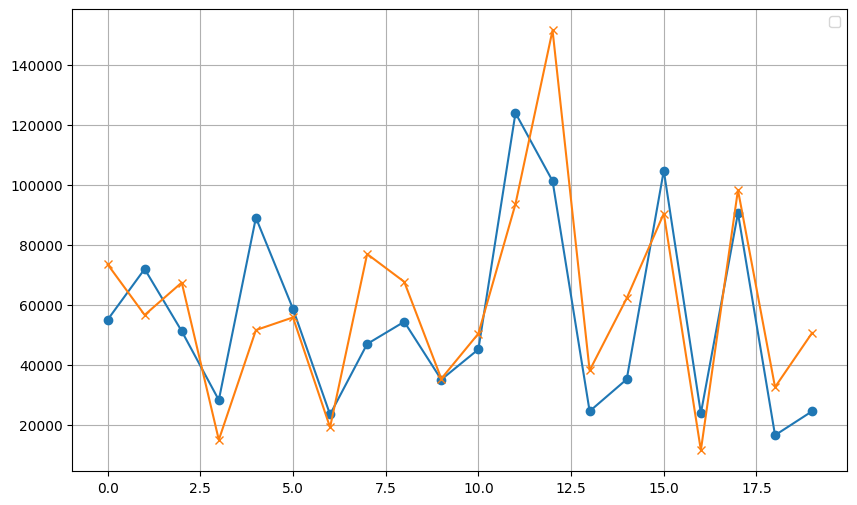

  7%|▋         | 1/15 [00:00<00:04,  3.05it/s]/tmp/ipykernel_6057/2174430653.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


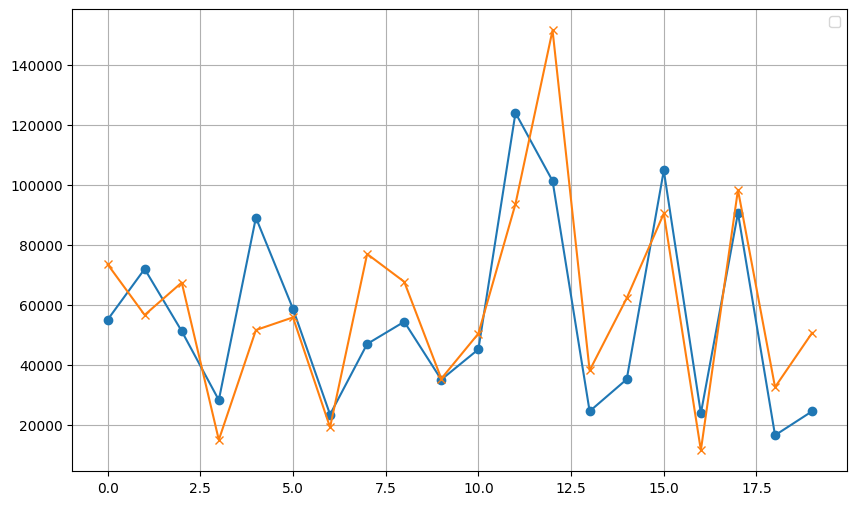

 13%|█▎        | 2/15 [00:00<00:03,  3.28it/s]/tmp/ipykernel_6057/2174430653.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


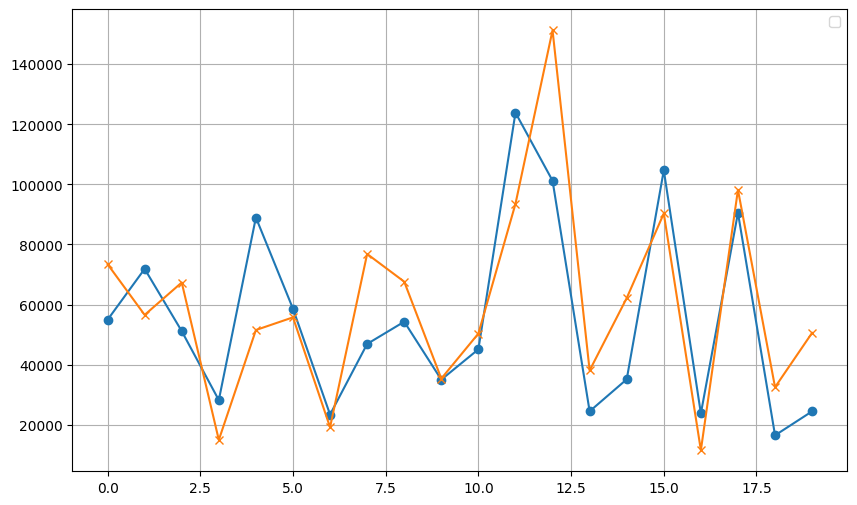

 20%|██        | 3/15 [00:00<00:03,  3.62it/s]/tmp/ipykernel_6057/2174430653.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


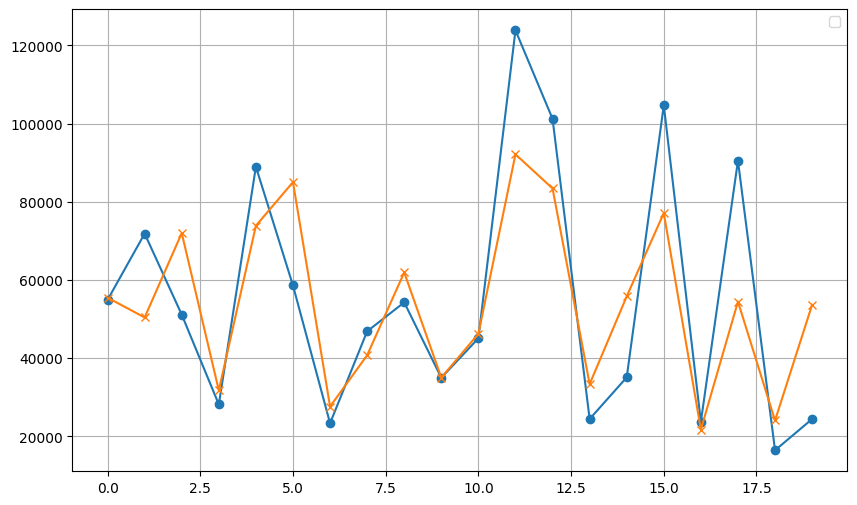

 27%|██▋       | 4/15 [00:01<00:02,  3.98it/s]/tmp/ipykernel_6057/2174430653.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


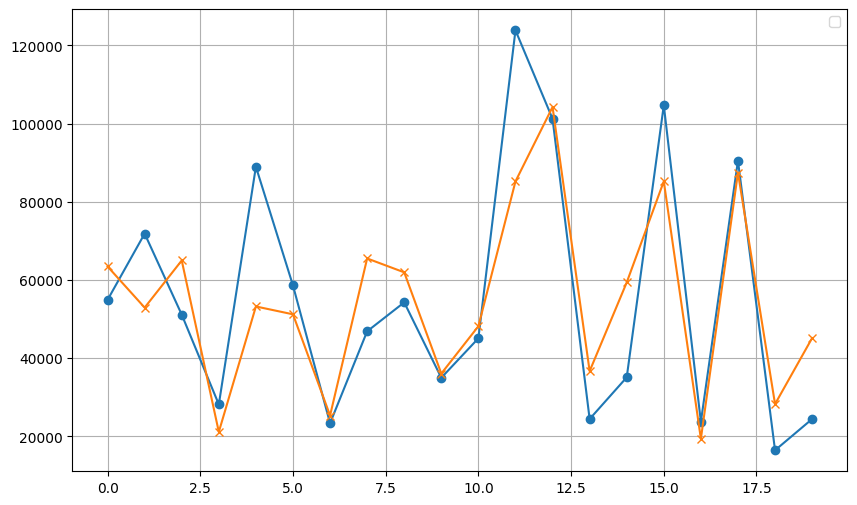

 33%|███▎      | 5/15 [00:01<00:02,  3.73it/s]/tmp/ipykernel_6057/2174430653.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


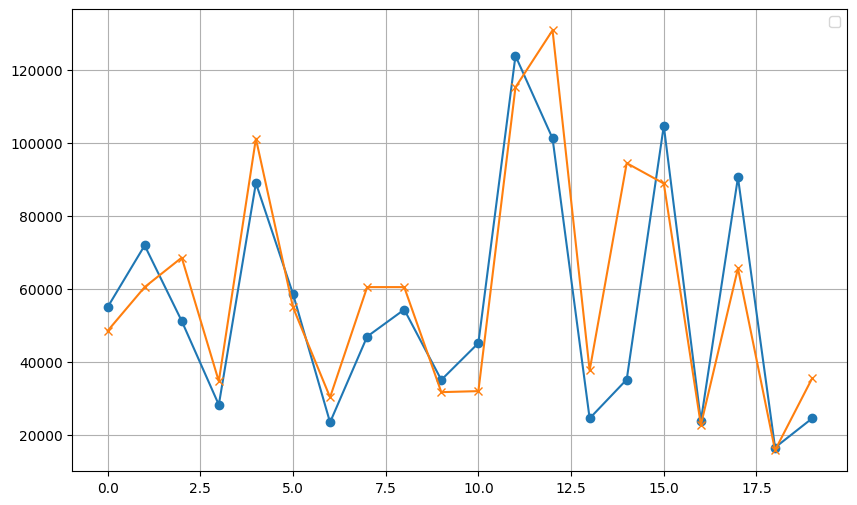

 40%|████      | 6/15 [00:01<00:02,  3.80it/s]/tmp/ipykernel_6057/2174430653.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


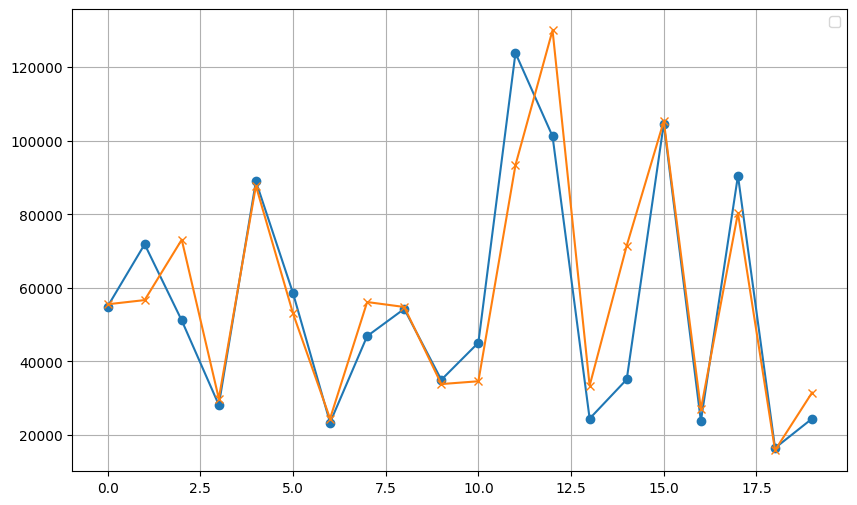

 47%|████▋     | 7/15 [00:02<00:04,  1.62it/s]/tmp/ipykernel_6057/2174430653.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


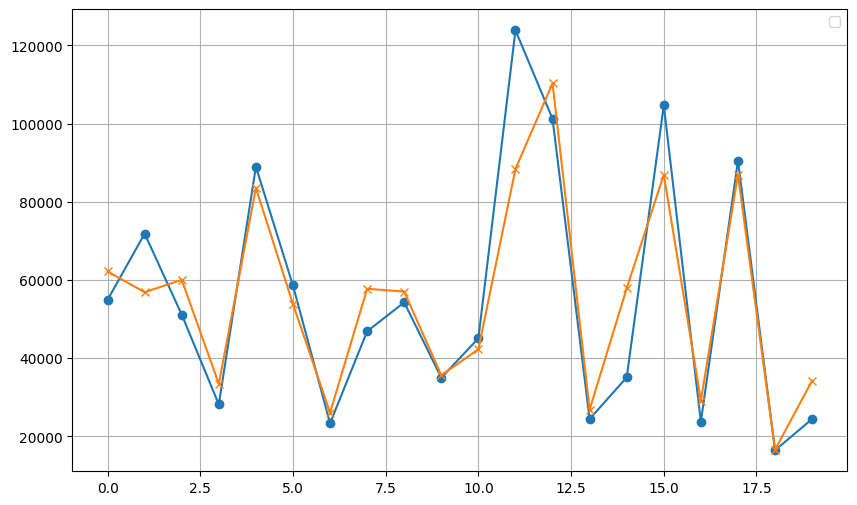

 53%|█████▎    | 8/15 [00:05<00:09,  1.37s/it]/tmp/ipykernel_6057/2174430653.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


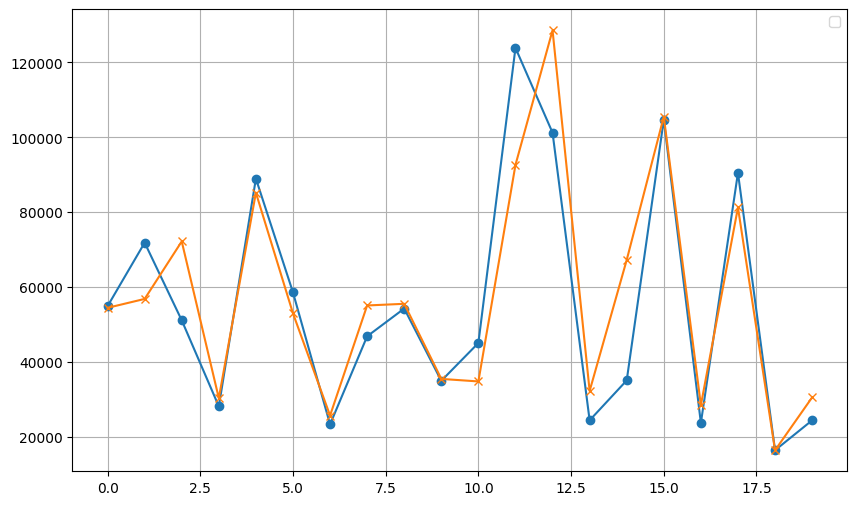

 60%|██████    | 9/15 [00:07<00:07,  1.27s/it]/tmp/ipykernel_6057/2174430653.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


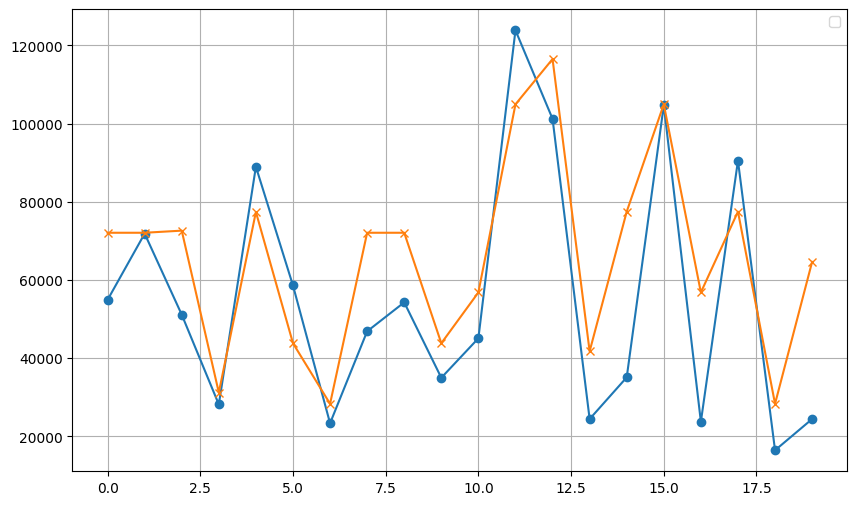

 67%|██████▋   | 10/15 [00:07<00:05,  1.06s/it]/tmp/ipykernel_6057/2174430653.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


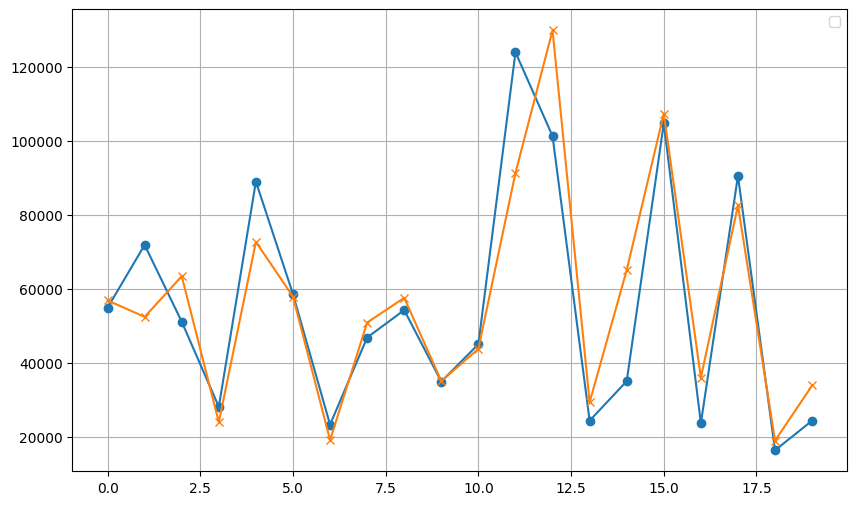

 73%|███████▎  | 11/15 [00:08<00:04,  1.00s/it]/tmp/ipykernel_6057/2174430653.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


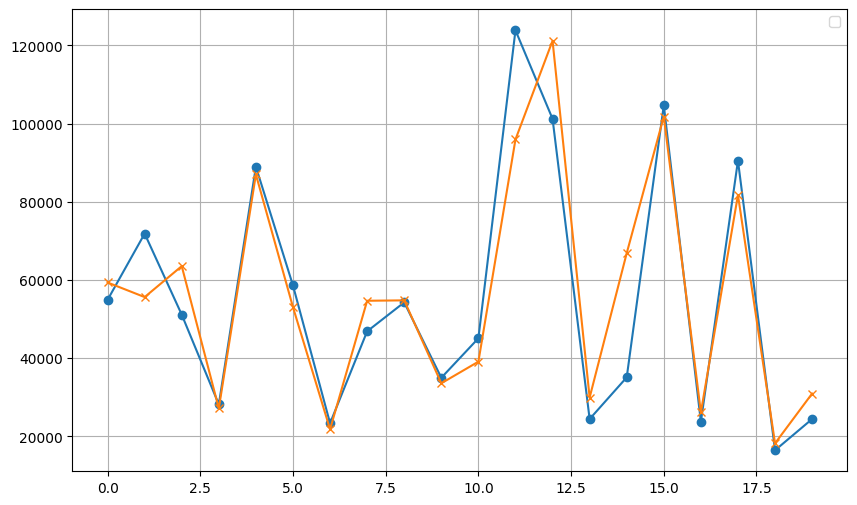

 80%|████████  | 12/15 [00:09<00:02,  1.04it/s]/tmp/ipykernel_6057/2174430653.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


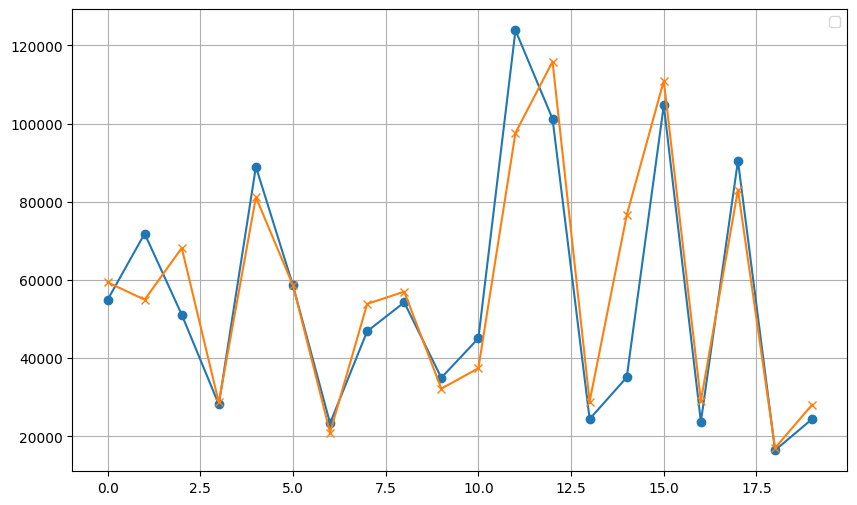

 87%|████████▋ | 13/15 [00:09<00:01,  1.16it/s]/tmp/ipykernel_6057/2174430653.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


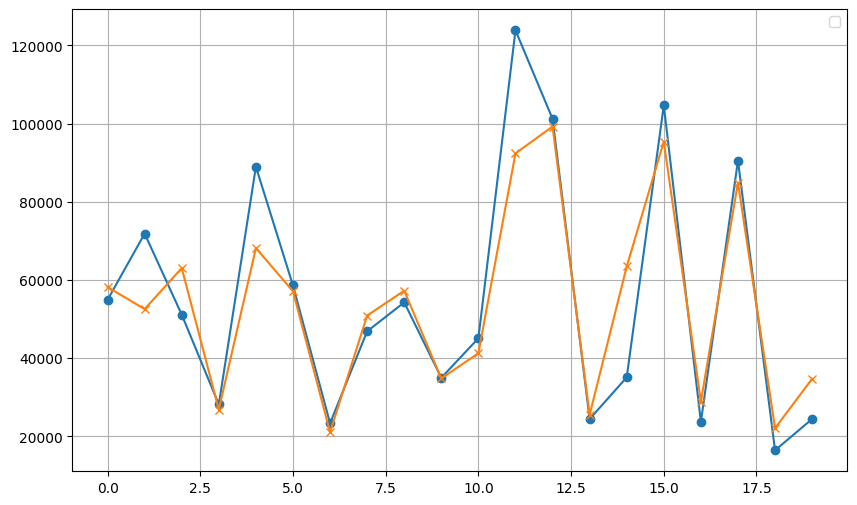

 93%|█████████▎| 14/15 [00:10<00:00,  1.16it/s]

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000392 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 527
[LightGBM] [Info] Number of data points in the train set: 1017, number of used features: 17
[LightGBM] [Info] Start training from score 60505.665871


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/tmp/ipykernel_6057/2174430653.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


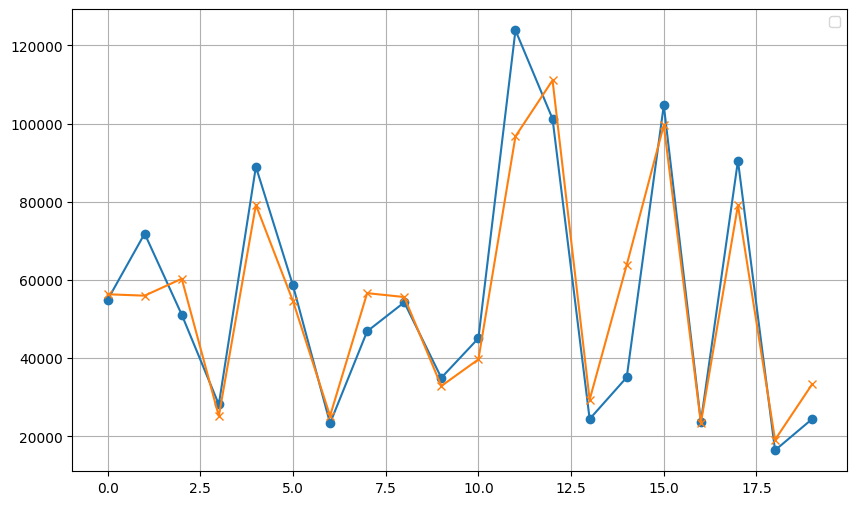

100%|██████████| 15/15 [00:11<00:00,  1.32it/s]


In [114]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)

    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, marker='o')
    plt.plot(range(20), y_pred_plot, marker='x')
    plt.legend()
    plt.grid()
    plt.show()

# **Votting Regressionn**


In [115]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, X_test, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, X_test, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, X_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }


# **Stacking Regression**

In [116]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [117]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [118]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
XGBoost,3679.130362,9230.115390,2.899495e+07,1.789607e+08,5384.695996,13377.620315,0.980013,0.845586
Stacking,4734.593006,9482.336345,6.725818e+07,2.211266e+08,8201.108224,14870.325996,0.953637,0.837721
LightGBM,4879.853396,9482.336345,6.596313e+07,2.211266e+08,8121.768858,14870.325996,0.954529,0.809204
HistGradientBoosting,4821.470543,9734.952651,6.520566e+07,2.261274e+08,8075.002043,15037.532685,0.955052,0.804889
GradientBoosting,8183.102800,10250.179795,1.230781e+08,2.313510e+08,11094.056267,15210.228127,0.915158,0.800382
ExtraTrees,0.031434,9660.880435,5.024351e-01,2.424664e+08,0.708827,15571.331931,1.000000,0.790791
Voting,6446.705003,9482.336345,8.996977e+07,2.211266e+08,9485.239467,14870.325996,0.937981,0.778236
Simple Voting,6446.705003,9482.336345,8.996977e+07,2.211266e+08,9485.239467,14870.325996,0.937981,0.778236
CatBoost,8490.242461,10169.675828,1.356626e+08,2.590931e+08,11647.430461,16096.369815,0.906483,0.776445
Random Forest,6209.309622,10451.618855,8.312577e+07,2.646191e+08,9117.333517,16267.117769,0.942699,0.771677


<Axes: >

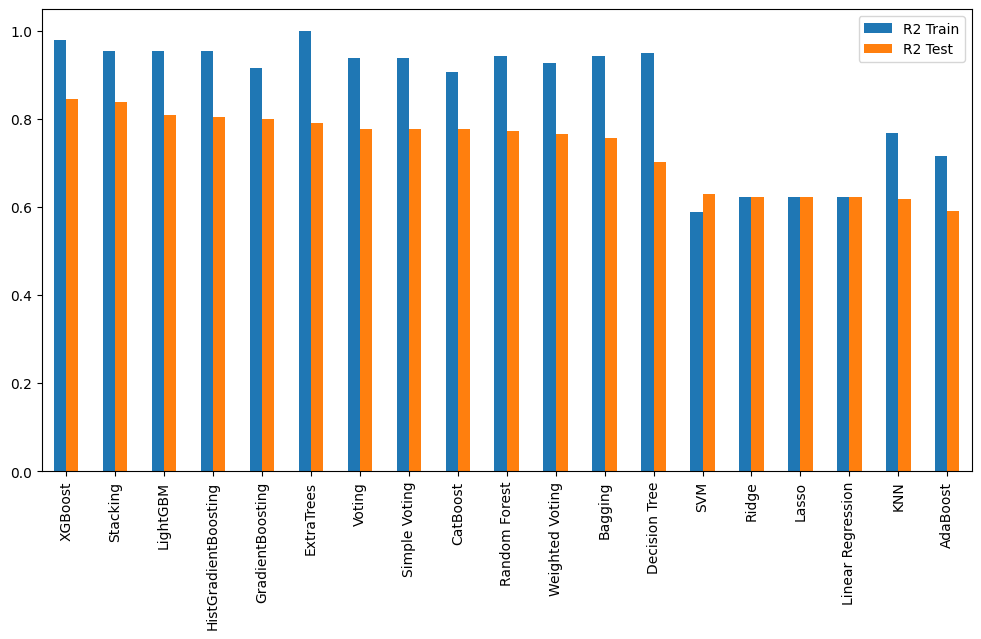

In [119]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

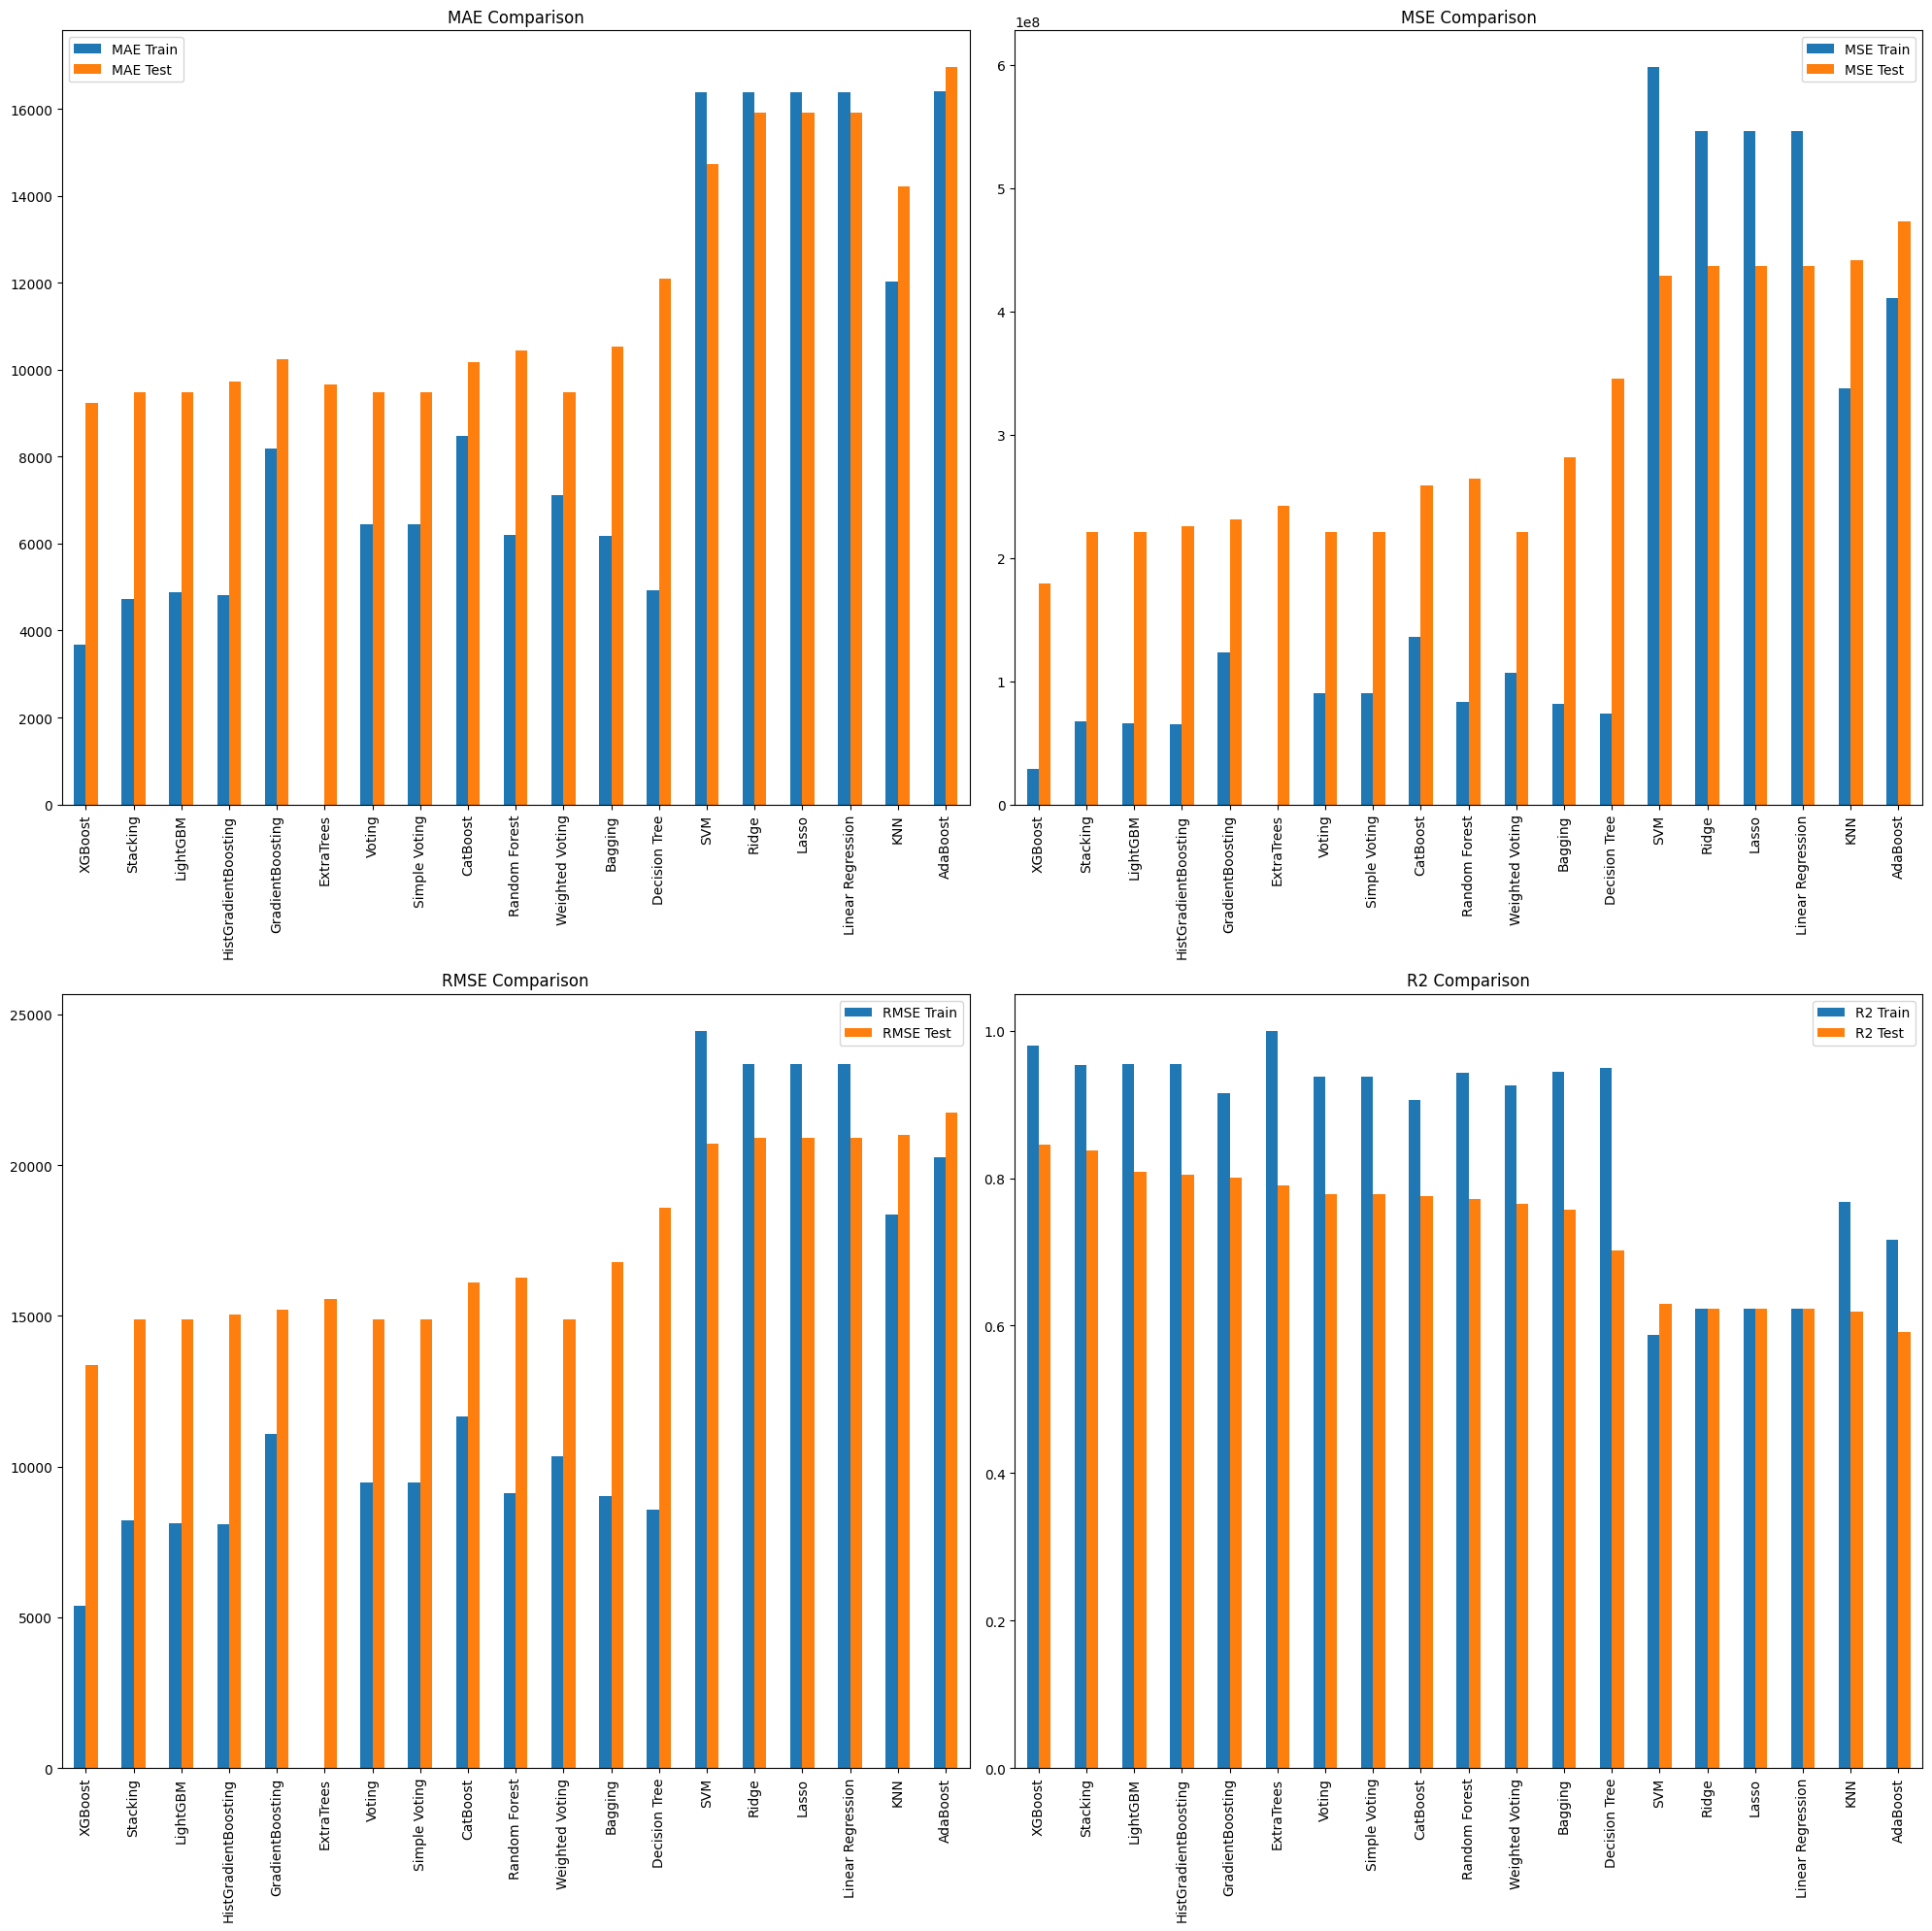

In [120]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()